# Wine Quality · EDA e agrupamento com K-Means

O objetivo é investigar se grupos de vinhos formados pelas características físico-químicas coincidem com as notas de qualidade e se a composição dos clusters está associada ao tipo de vinho.

## EDA estrutural

Os dois arquivos são empilhados, e a coluna `tipo_vinho` identifica tintos e brancos. A base combinada tem 13 colunas: 11 medidas numéricas, a nota ordinal `quality` e o tipo de vinho, que é categórico nominal.

In [1]:
import pandas as pd
from IPython.display import display

tintos = pd.read_csv("../../data/parte_comum/winequality-red.csv", sep=";")
brancos = pd.read_csv("../../data/parte_comum/winequality-white.csv", sep=";")

tintos["tipo_vinho"] = "tinto"
brancos["tipo_vinho"] = "branco"

vinhos = pd.concat([tintos, brancos], ignore_index=True)

print(f"Dimensões da base combinada: {vinhos.shape}")
display(vinhos.head())

# [IA] Claude – pasta de saída das figuras exportadas.
from pathlib import Path

SAIDA = Path("../../out/parte_comum")
SAIDA.mkdir(parents=True, exist_ok=True)


Dimensões da base combinada: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vinho
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


In [2]:
estrutura = pd.DataFrame({
    "tipo_de_dado": vinhos.dtypes.astype(str),
    "valores_ausentes": vinhos.isna().sum(),
    "valores_distintos": vinhos.nunique(),
})

display(estrutura)

print(f"Linhas repetidas além da primeira ocorrência: {vinhos.duplicated().sum()}")

,tipo_de_dado,valores_ausentes,valores_distintos
fixed acidity,float64,0,106
volatile acidity,float64,0,187
citric acid,float64,0,89
residual sugar,float64,0,316
chlorides,float64,0,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,0,108
sulphates,float64,0,111


Linhas repetidas além da primeira ocorrência: 1177


A base combinada tem **6.497 amostras** e nenhum valor ausente. Foram encontradas **1.177 linhas repetidas além da primeira ocorrência**. Mantivemos essas linhas, pois os arquivos identificam as amostras por suas características registradas, sem um identificador que permita confirmar se linhas iguais correspondem ao mesmo vinho registrado duas vezes. A presença de linhas repetidas pode dar mais peso a certas combinações de medidas no ajuste do K-Means.

## EDA distribucional

As contagens por nota e tipo mostram o tamanho de cada grupo. O gráfico usa percentuais dentro de cada tipo para permitir a comparação entre brancos e tintos, que têm tamanhos diferentes.

In [3]:
notas_por_tipo = pd.crosstab(
    index=vinhos["quality"],
    columns=vinhos["tipo_vinho"],
    margins=True,
    margins_name="Total",
)

display(notas_por_tipo)

# [IA] Claude – conversão para int, para exibir as notas sem o prefixo np.int64.
classes = [int(nota) for nota in sorted(vinhos["quality"].dropna().unique())]
k_fixo = len(classes)

print(f"Notas observadas: {classes}")
print(f"k da segunda passada: {k_fixo}")

tipo_vinho,branco,tinto,Total
quality,,,
3,20,10,30
4,163,53,216
5,1457,681,2138
6,2198,638,2836
7,880,199,1079
8,175,18,193
9,5,0,5
Total,4898,1599,6497


Notas observadas: [3, 4, 5, 6, 7, 8, 9]
k da segunda passada: 7


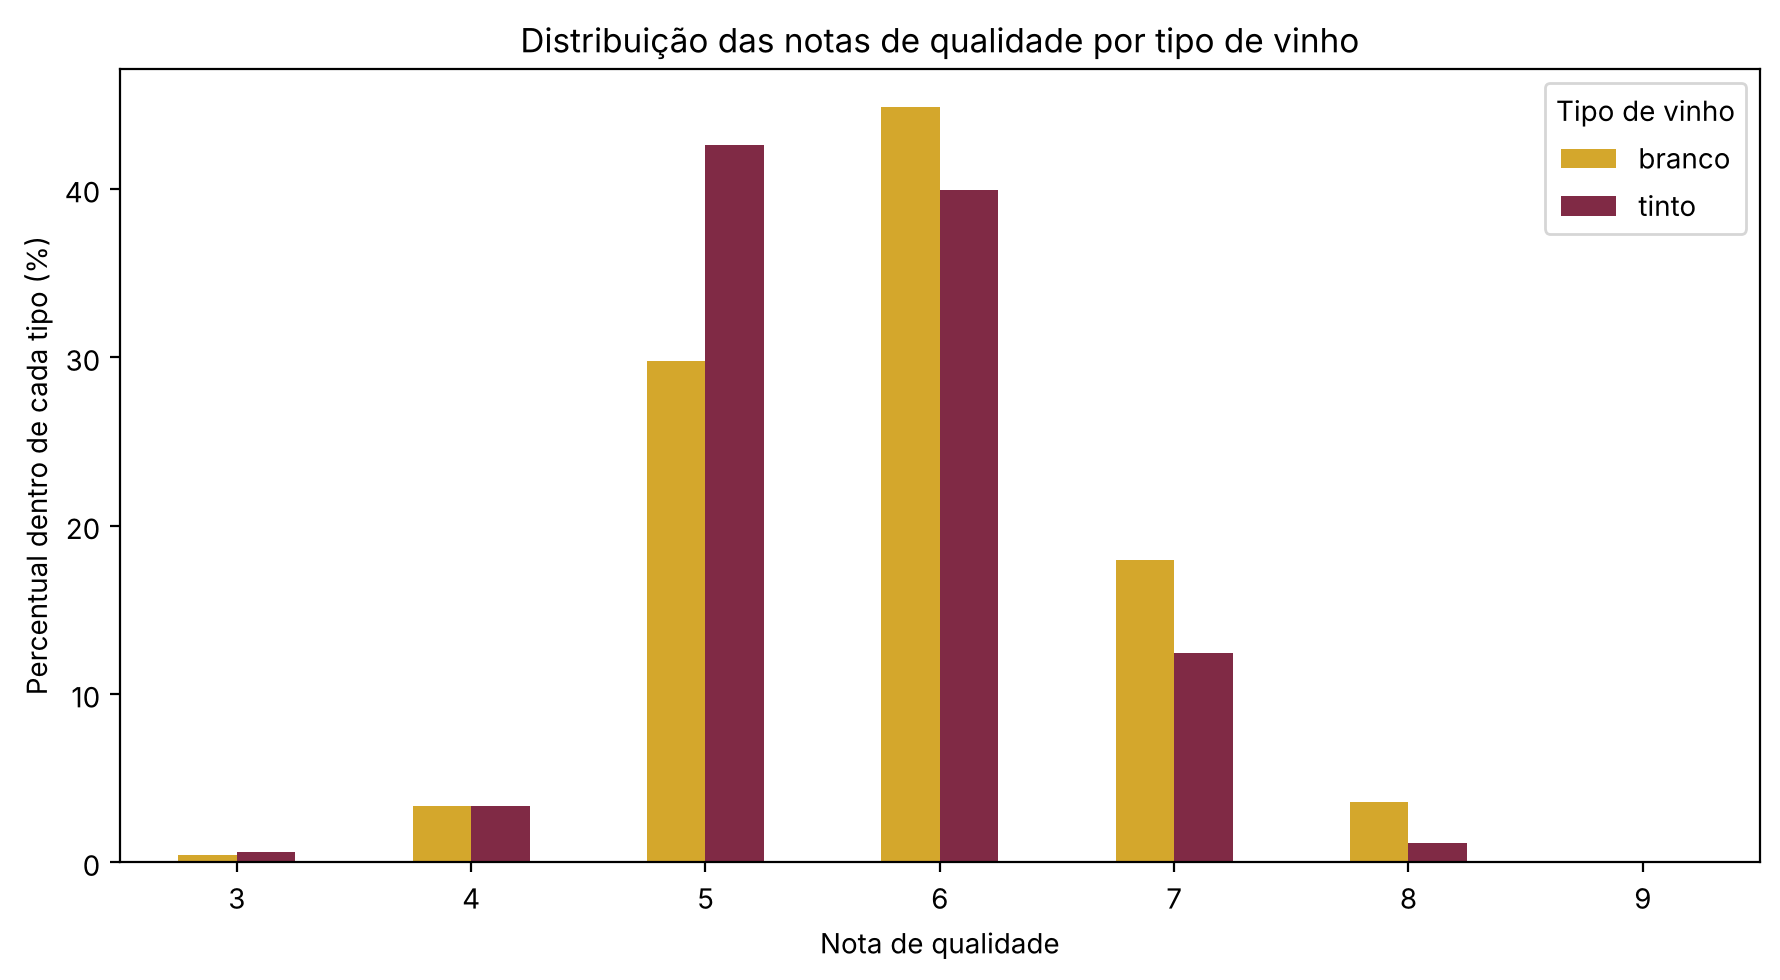

In [4]:
import matplotlib.pyplot as plt

percentual_por_tipo = pd.crosstab(
    vinhos["quality"],
    vinhos["tipo_vinho"],
    normalize="columns",
).mul(100)

ax = percentual_por_tipo.plot.bar(
    figsize=(9, 5),
    color=["#D4A72C", "#802A45"],
    rot=0,
)

ax.set_title("Distribuição das notas de qualidade por tipo de vinho")
ax.set_xlabel("Nota de qualidade")
ax.set_ylabel("Percentual dentro de cada tipo (%)")
ax.legend(title="Tipo de vinho")

plt.tight_layout()
# [IA] Claude – exportação da figura para out/parte_comum.
plt.savefig(SAIDA / "distribuicao_notas_por_tipo.png", dpi=150, bbox_inches="tight")
plt.show()

As notas 5 e 6 representam 76,6% da base combinada. Entre os vinhos brancos, a nota mais frequente é 6 (44,9%). Entre os tintos, é 5 (42,6%). Essa concentração ajuda a interpretar a avaliação do K-Means: mesmo com sete clusters, a regra da classe majoritária pode atribuir a mesma nota a vários grupos e deixar notas raras sem nenhum grupo associado. Por isso, vamos analisar o recall de cada nota junto com a acurácia global.

In [5]:
medidas_fisico_quimicas = vinhos.drop(columns=["quality", "tipo_vinho"])

resumo = medidas_fisico_quimicas.describe().T.rename(
    columns={
        "count": "observações",
        "mean": "média",
        "std": "desvio padrão",
        "min": "mínimo",
        "25%": "Q1",
        "50%": "mediana",
        "75%": "Q3",
        "max": "máximo",
    }
)

display(resumo.round(3))

,observações,média,desvio padrão,mínimo,Q1,mediana,Q3,máximo
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


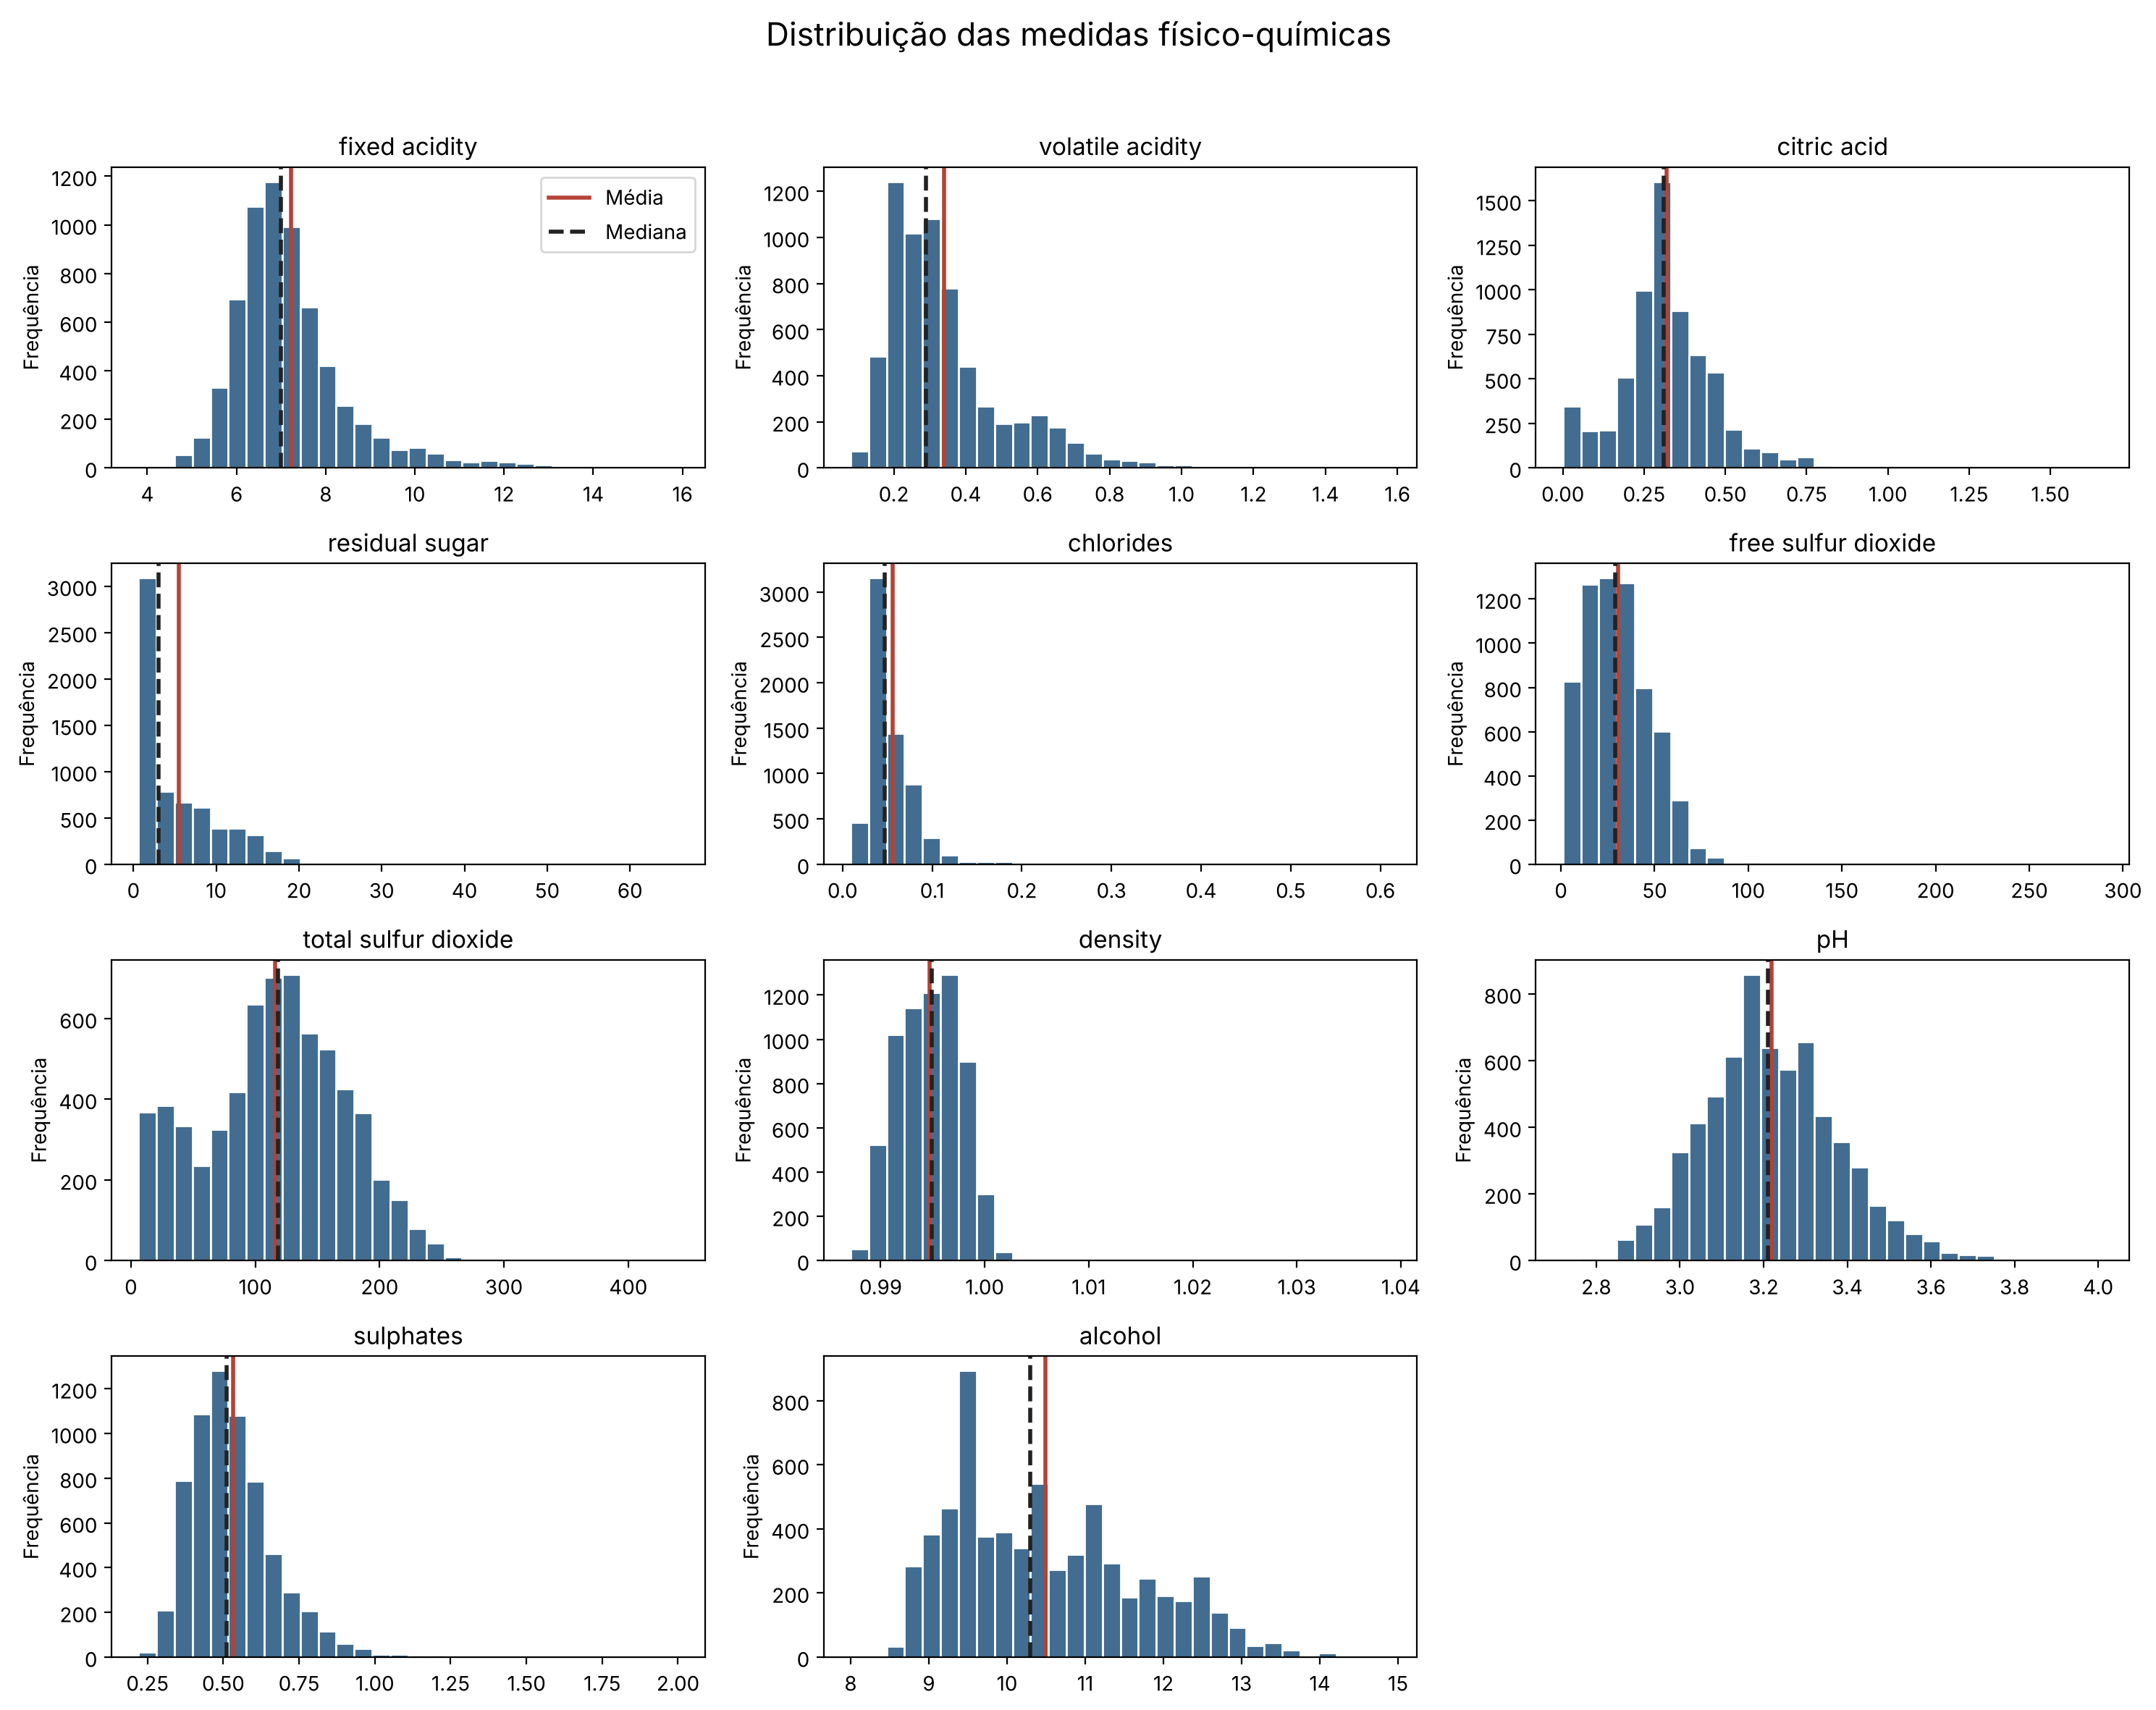

In [6]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(4, 3, figsize=(15, 12))

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    valores = medidas_fisico_quimicas[coluna]

    ax.hist(valores, bins=30, color="#426D91", edgecolor="white")
    ax.axvline(valores.mean(), color="#B54235", linewidth=2, label="Média")
    ax.axvline(
        valores.median(),
        color="#222222",
        linestyle="--",
        linewidth=2,
        label="Mediana",
    )

    ax.set_title(coluna)
    ax.set_ylabel("Frequência")

eixos.flat[-1].set_visible(False)
eixos.flat[0].legend()

fig.suptitle("Distribuição das medidas físico-químicas", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
# [IA] Claude – exportação da figura para out/parte_comum.
fig.savefig(SAIDA / "histogramas_medidas.png", dpi=150, bbox_inches="tight")
plt.show()

O açúcar residual teve mediana de **3,00**, média de **5,44** e máximo de **65,8**. O contraste entre a concentração de valores baixos e a cauda de valores altos no histograma indica assimetria à direita.

## EDA relacional

A matriz de Spearman resume as associações entre pares de medidas. Os boxplots comparam as distribuições de cada medida por nota e por tipo de vinho.

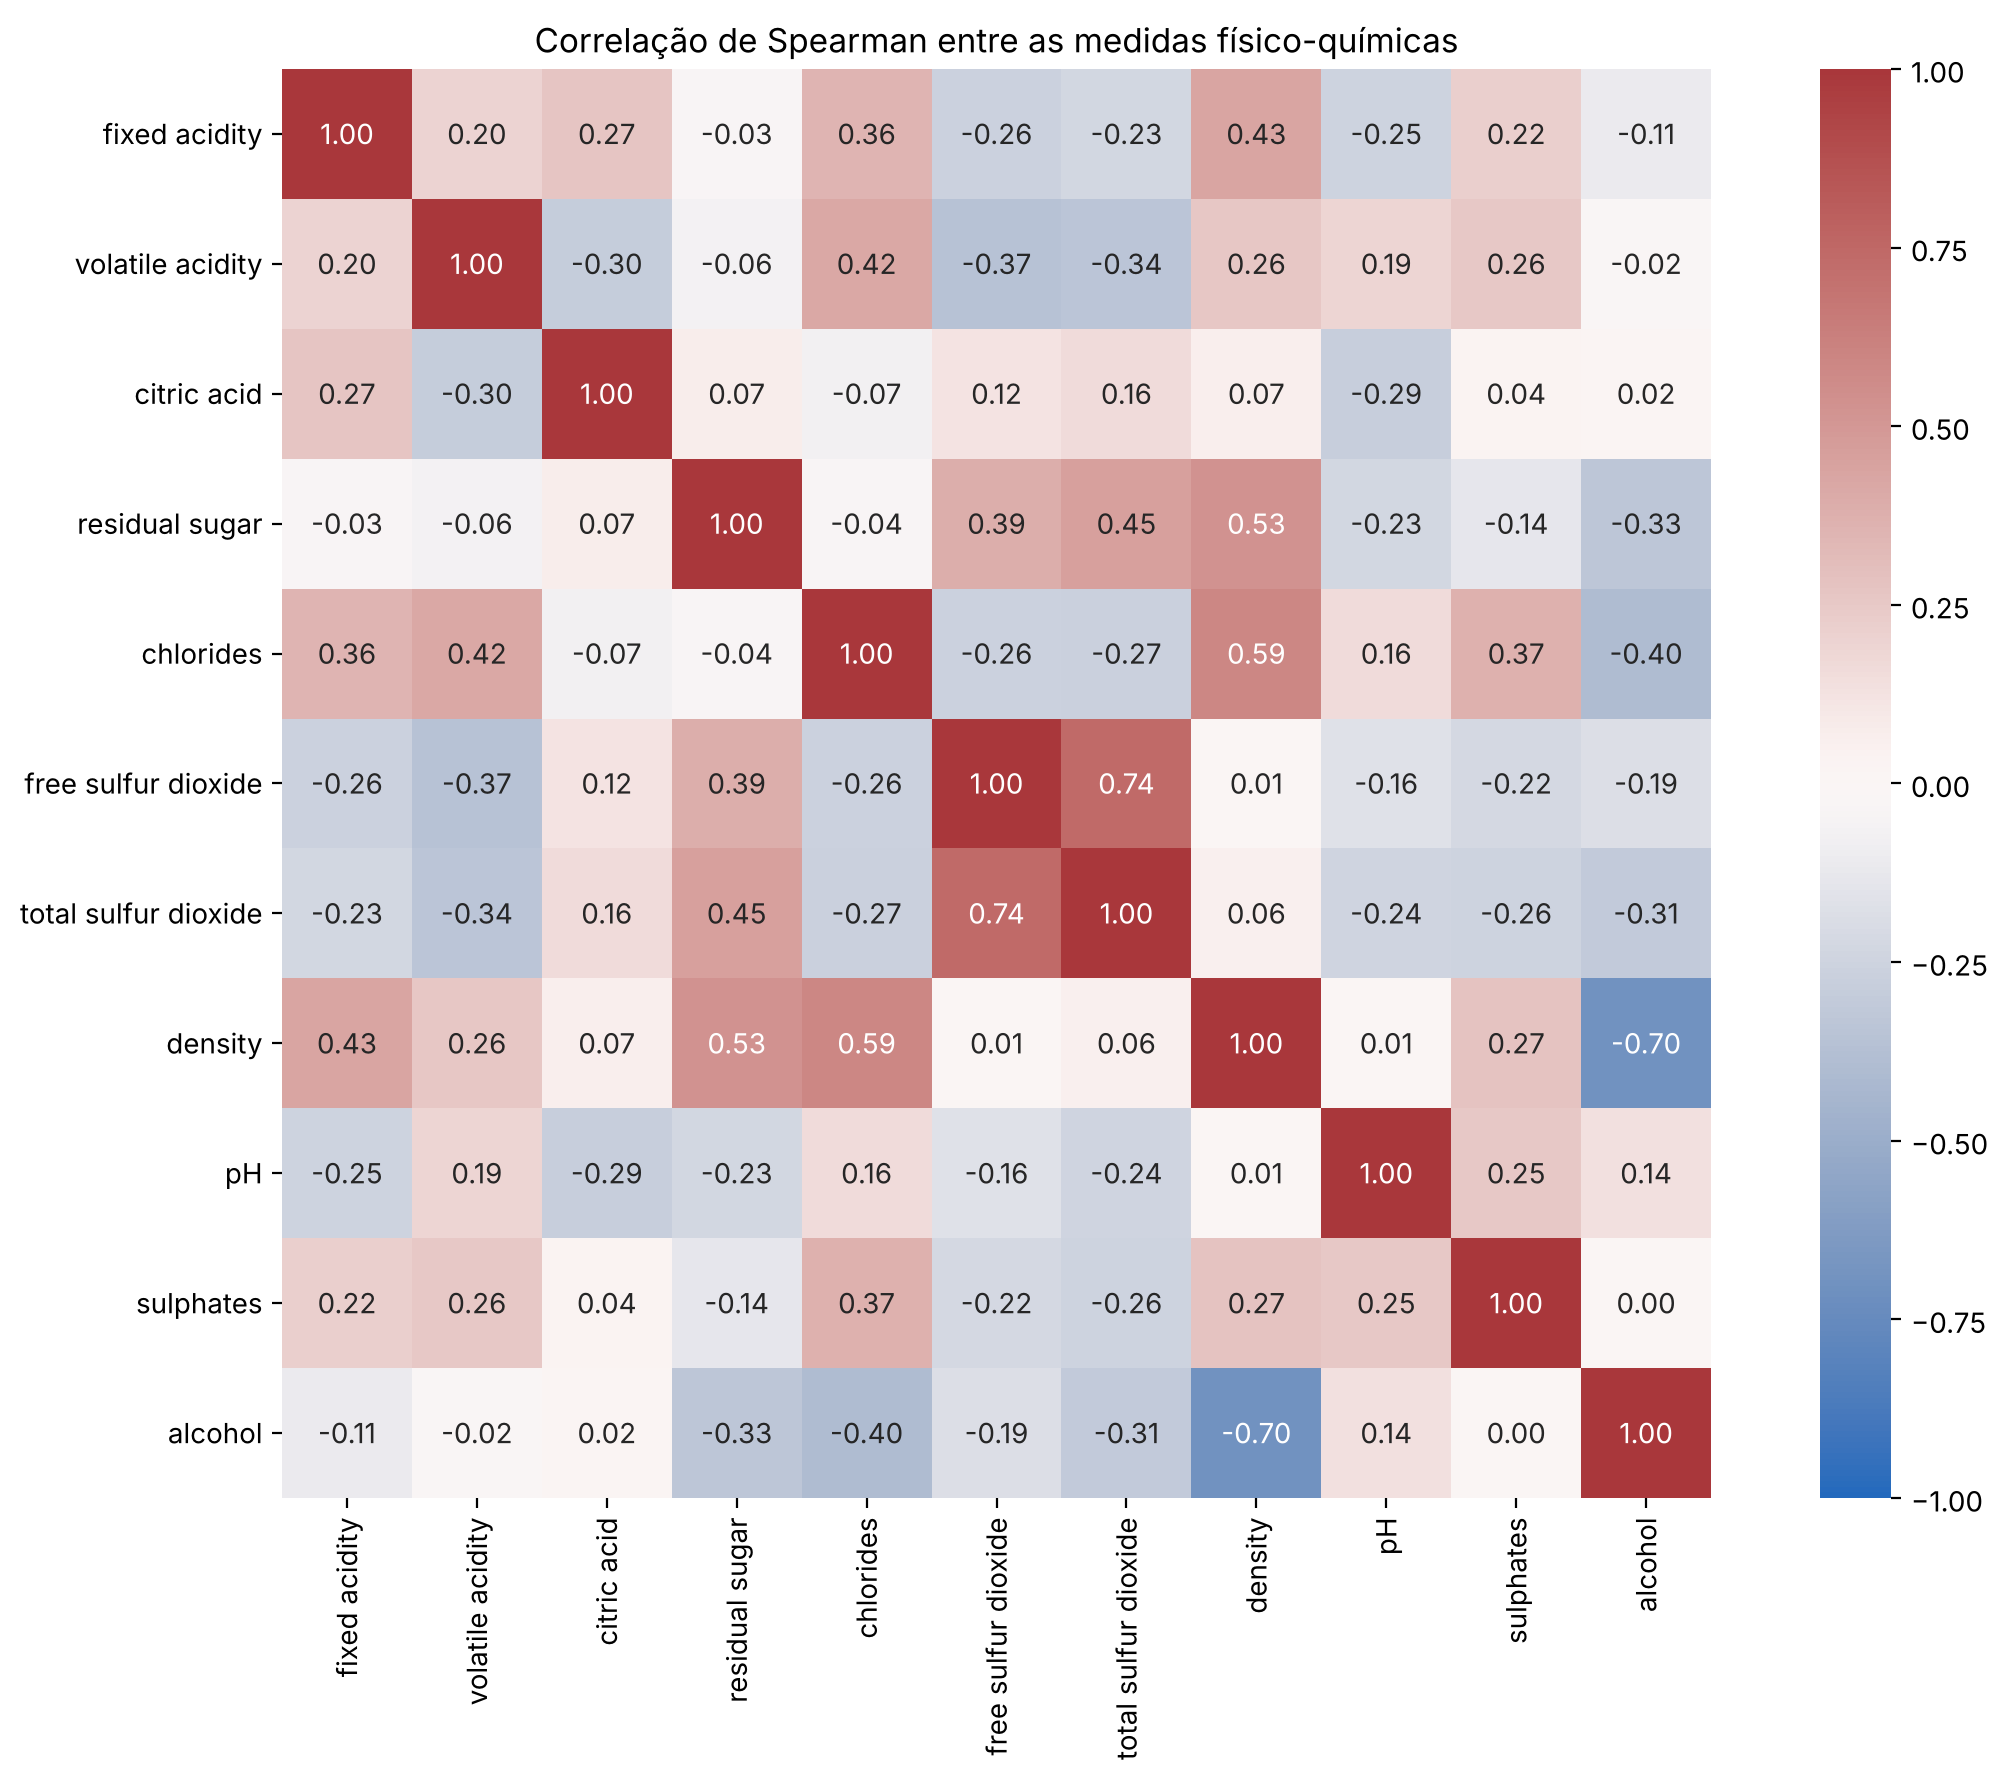

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

correlacoes = medidas_fisico_quimicas.corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Correlação de Spearman entre as medidas físico-químicas")
plt.tight_layout()
# [IA] Claude – exportação da figura para out/parte_comum.
plt.savefig(SAIDA / "correlacao_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

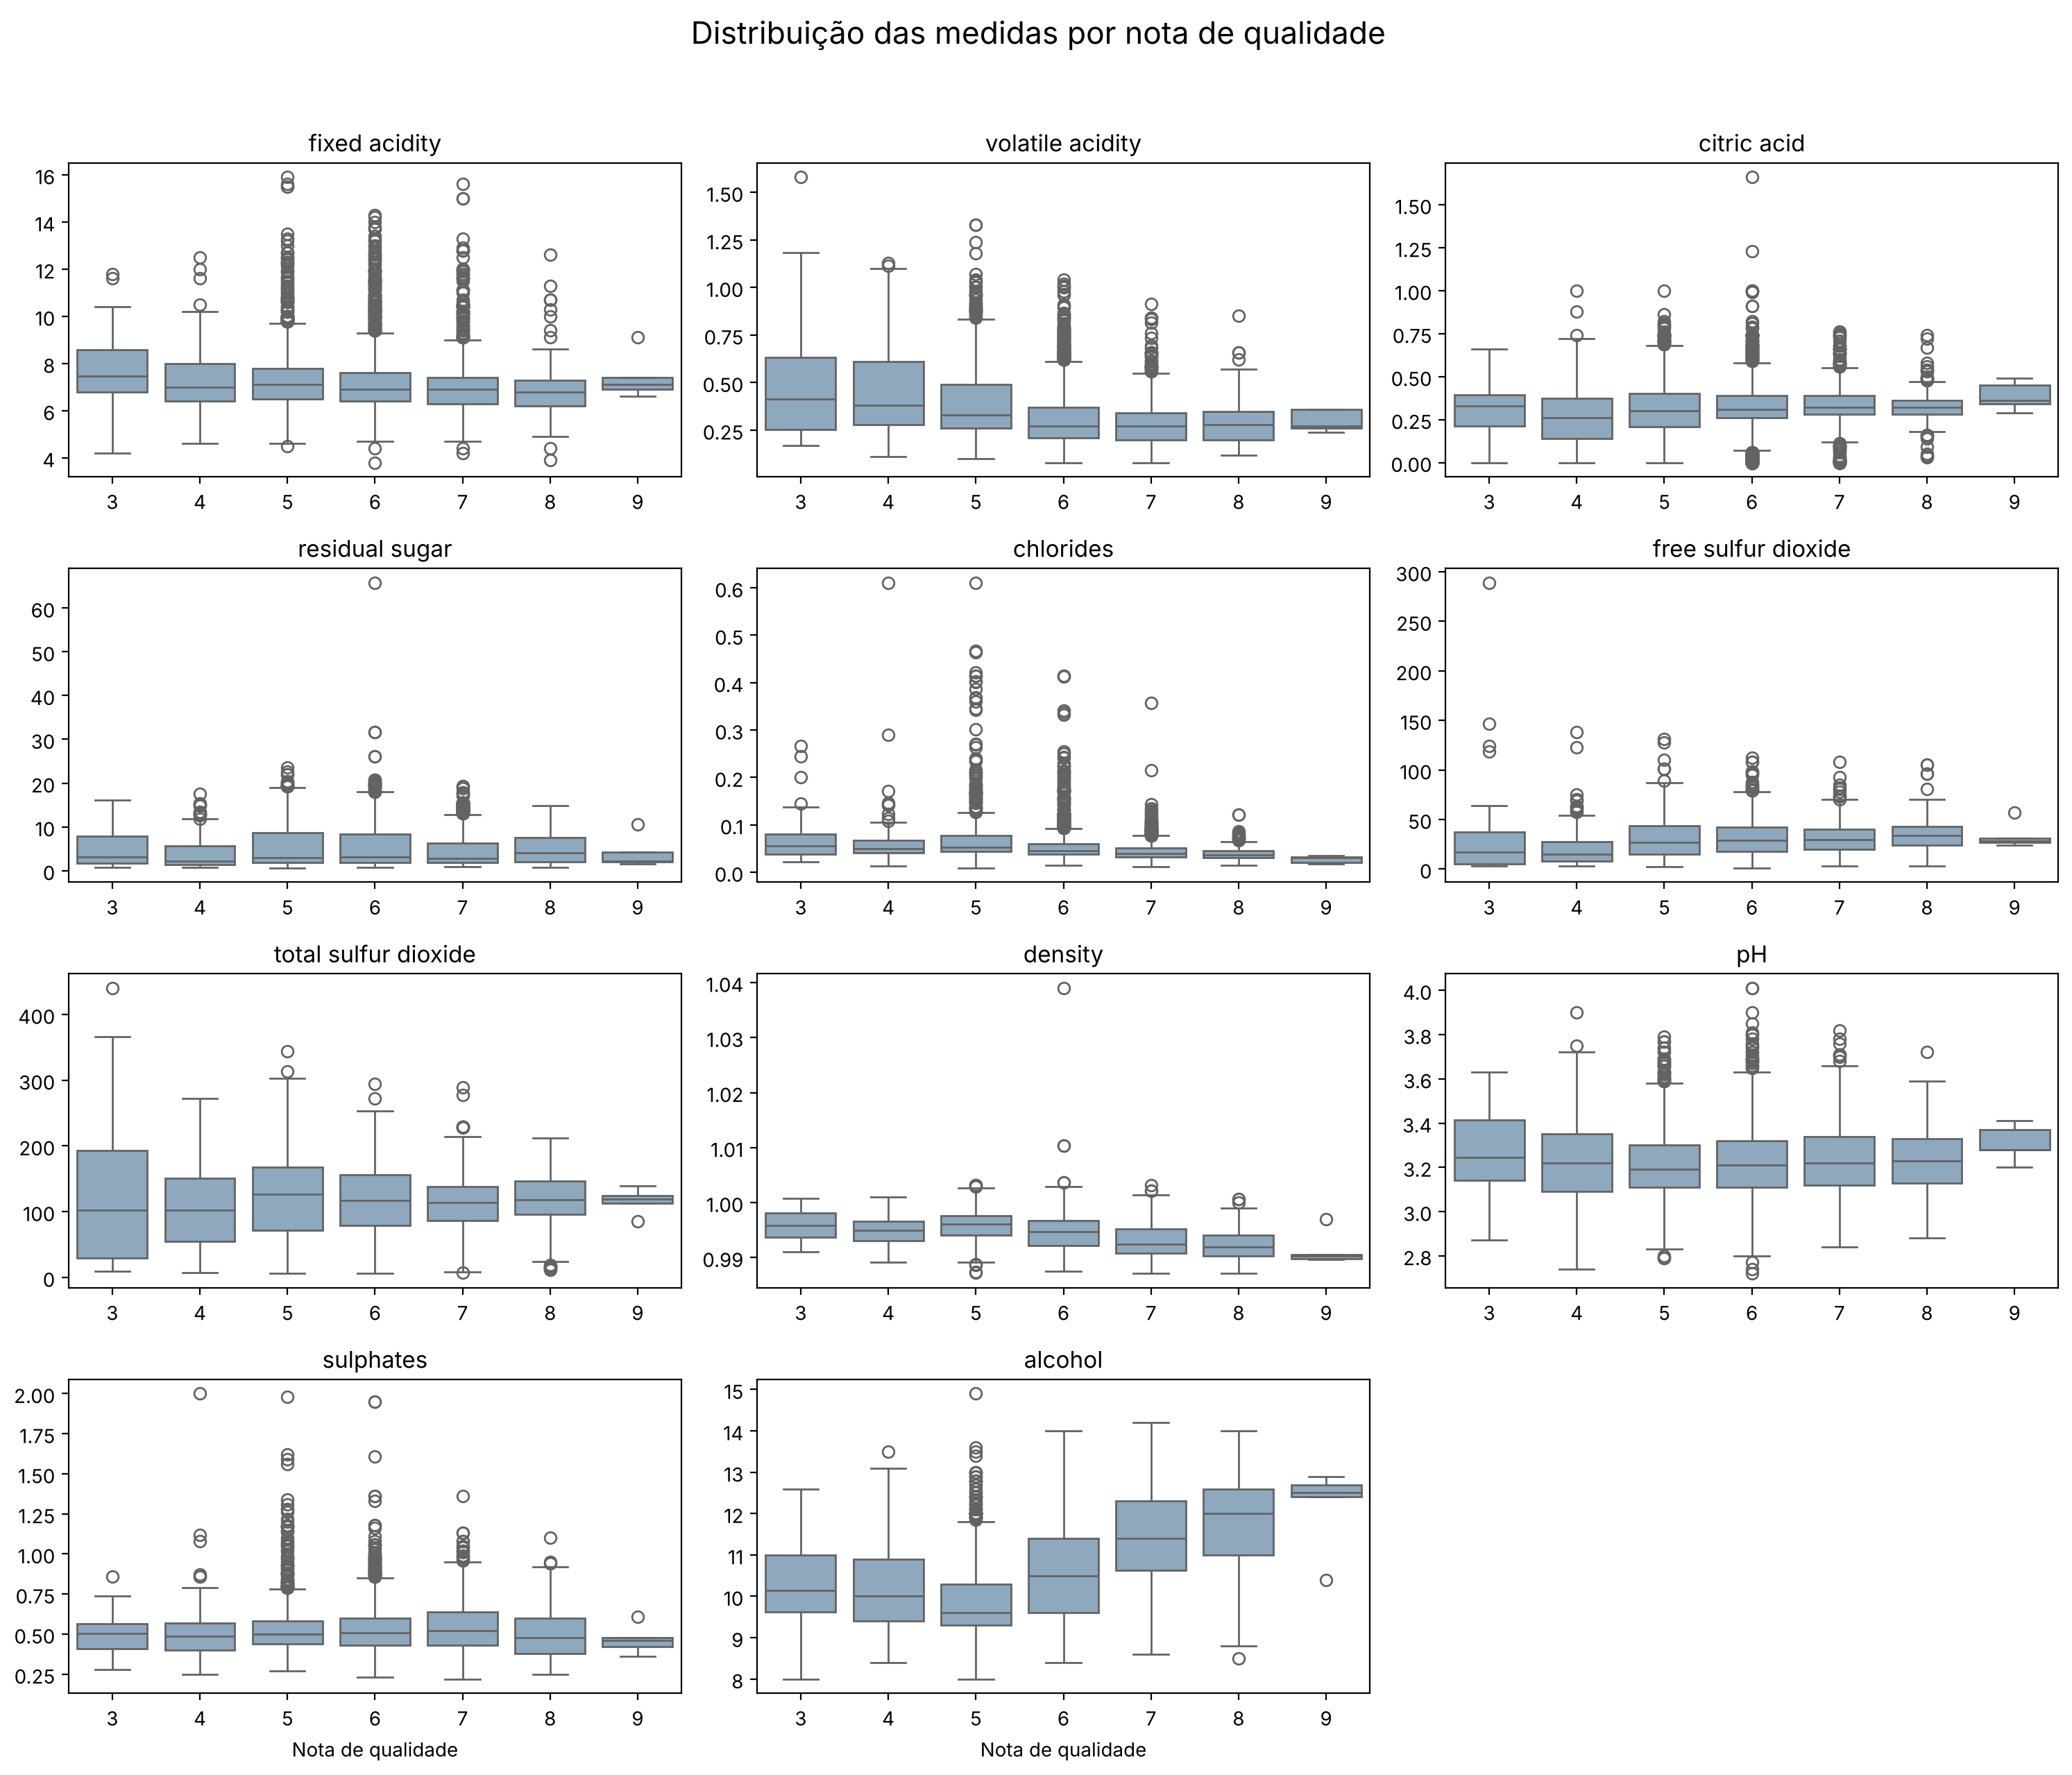

In [8]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 13), sharex=True)

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    sns.boxplot(
        data=vinhos,
        x="quality",
        y=coluna,
        order=classes,
        color="#86A9C5",
        ax=ax,
    )
    ax.set_title(coluna)
    ax.set_xlabel("Nota de qualidade")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelbottom=True)

eixos.flat[-1].set_visible(False)
fig.suptitle("Distribuição das medidas por nota de qualidade", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
# [IA] Claude – exportação da figura para out/parte_comum.
fig.savefig(SAIDA / "boxplots_por_nota.png", dpi=150, bbox_inches="tight")
plt.show()

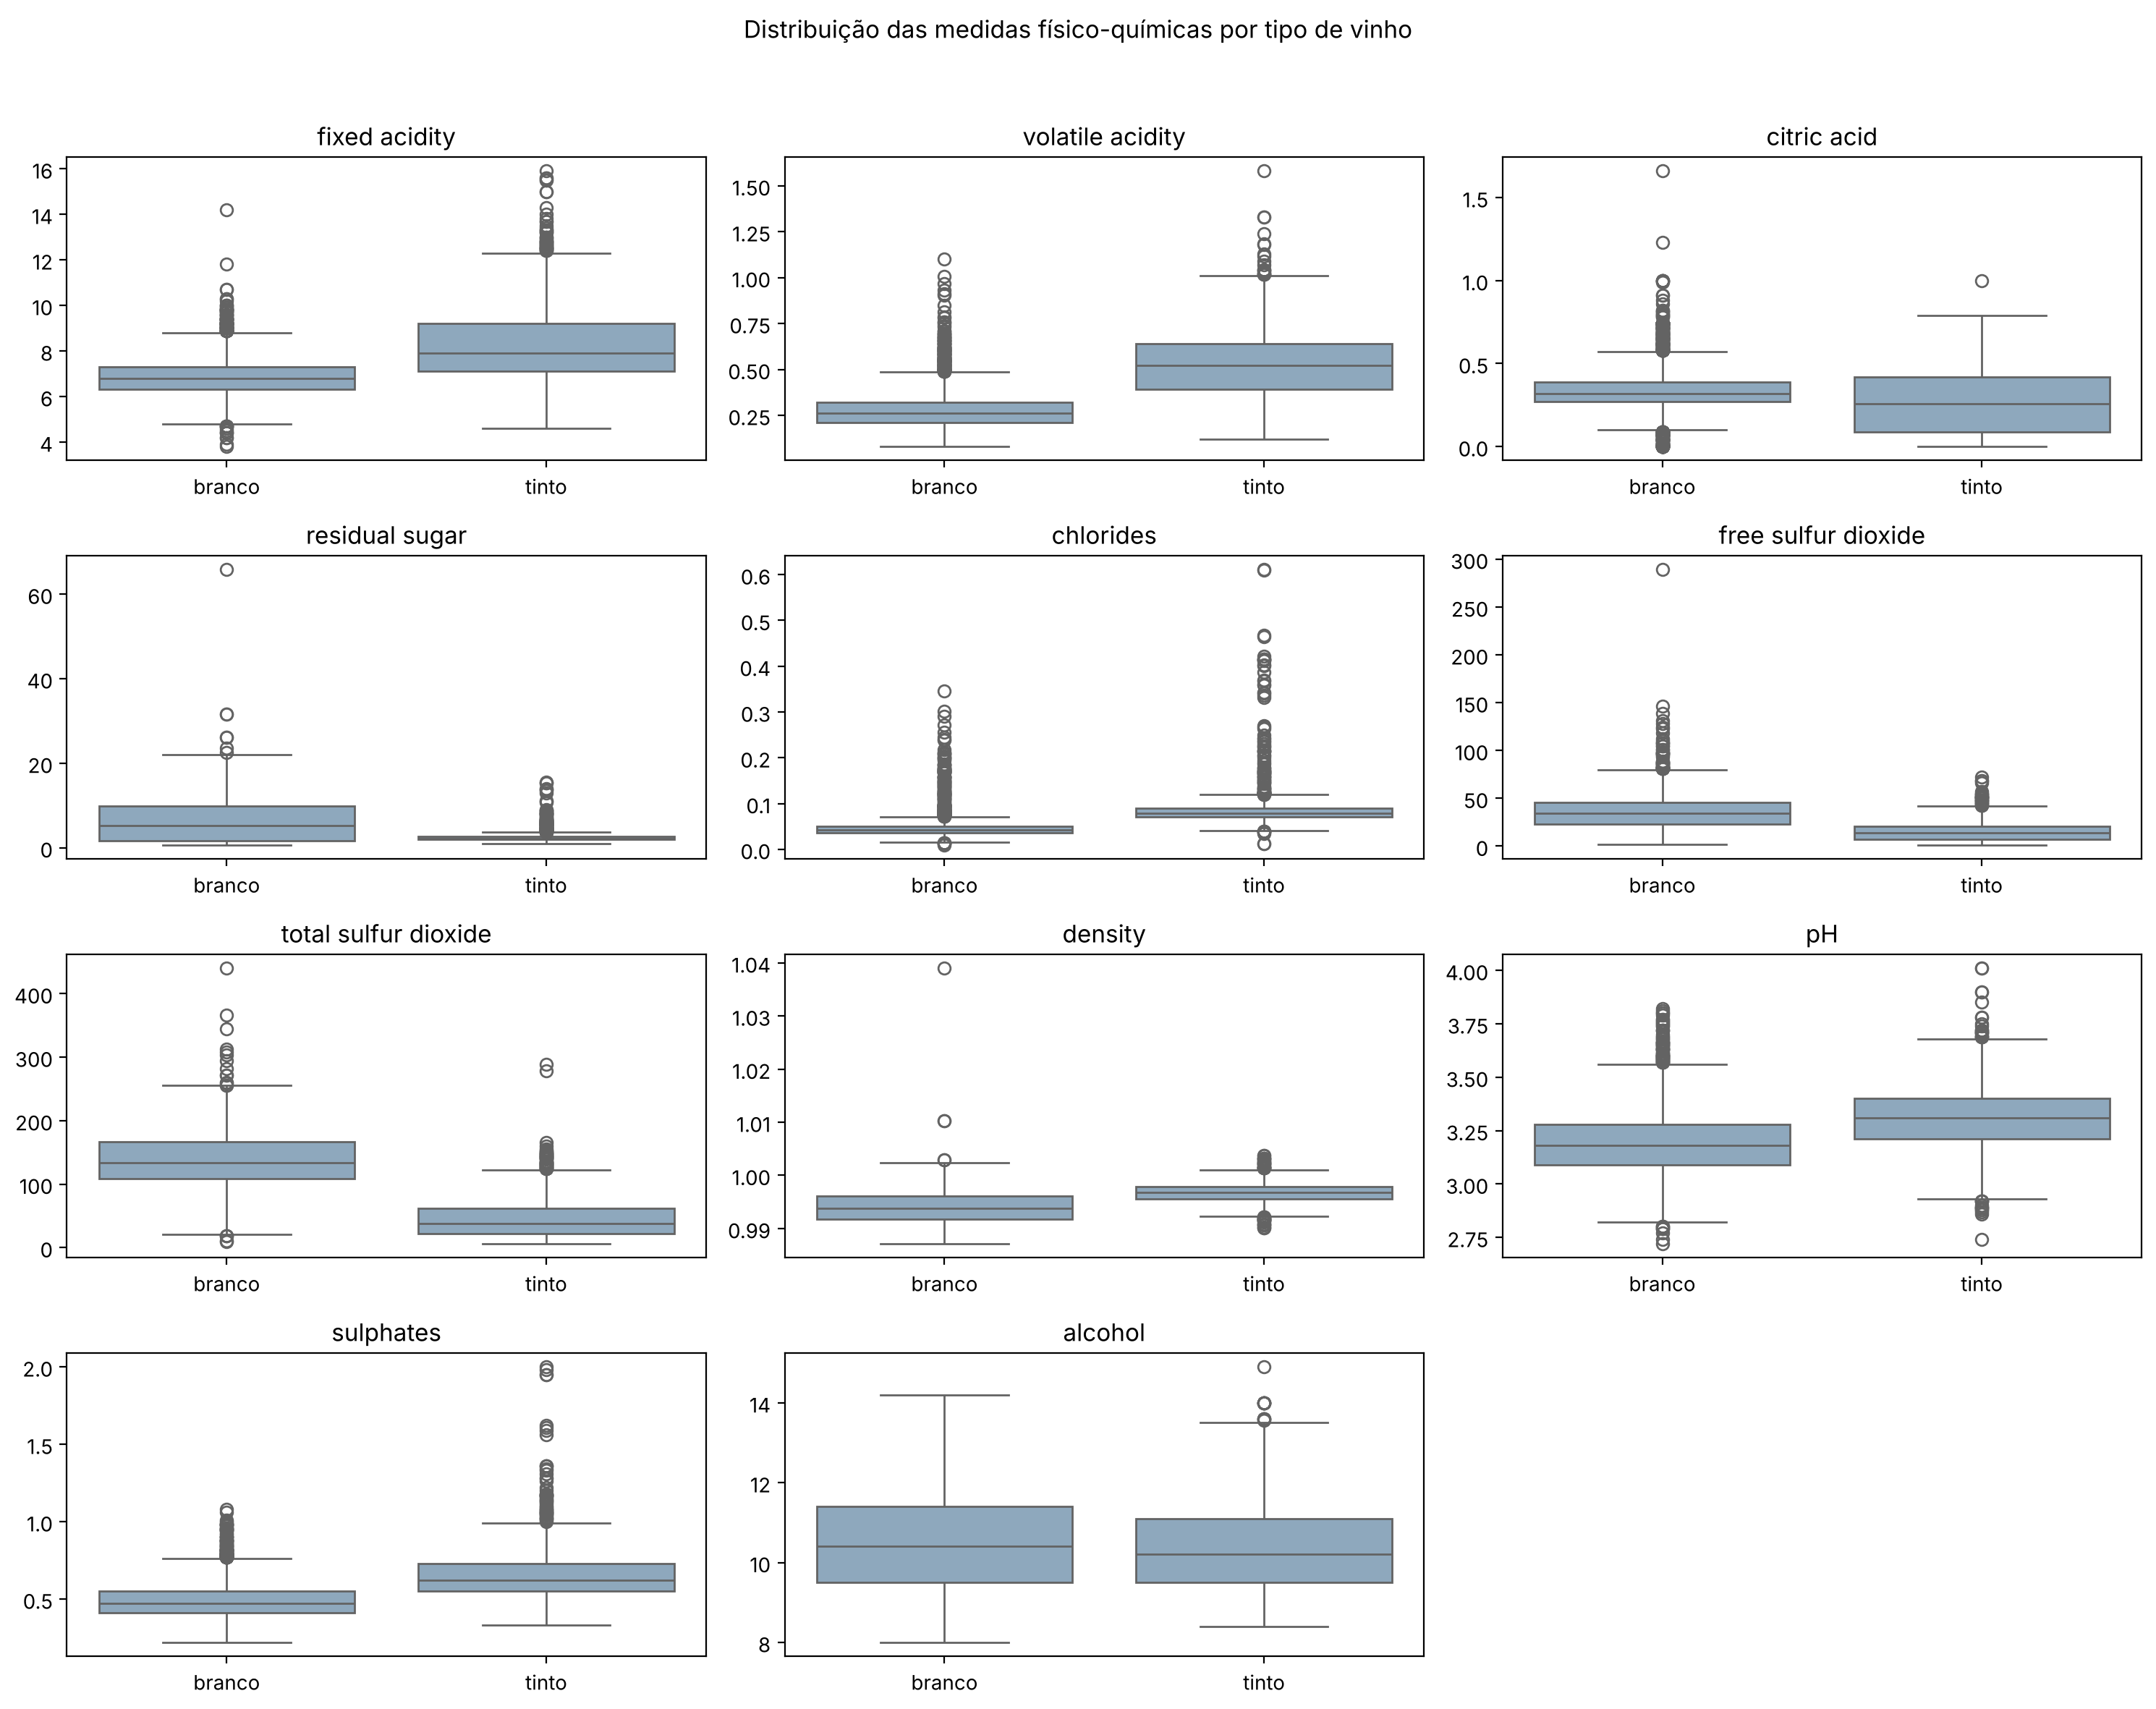

In [9]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 12))

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    sns.boxplot(
        data=vinhos,
        x="tipo_vinho",
        y=coluna,
        order=["branco", "tinto"],
        color="#86A9C5",
        ax=ax,
    )
    ax.set_title(coluna)
    ax.set_xlabel("")
    ax.set_ylabel("")

eixos.flat[-1].set_visible(False)
fig.suptitle("Distribuição das medidas físico-químicas por tipo de vinho")
fig.tight_layout(rect=(0, 0, 1, 0.96))
# [IA] Claude – exportação da figura para out/parte_comum.
fig.savefig(SAIDA / "boxplots_por_tipo.png", dpi=150, bbox_inches="tight")
plt.show()

O dióxido de enxofre livre e o total apresentaram correlação de Spearman de **0,74**. Densidade e teor alcoólico apresentaram correlação de **−0,70**. Os coeficientes descrevem associações na base combinada.

A mediana do teor alcoólico sobe da nota 5 para a 6 e segue aumentando até a 8, com sobreposição entre as distribuições. Em açúcar residual, as notas 5 e 6 têm medianas próximas e caixas bastante sobrepostas. Por tipo, o dióxido de enxofre total apresenta uma separação visual clara entre as caixas dos brancos e dos tintos. Essa diferença ajuda a formular a hipótese de que os clusters possam refletir o tipo de vinho.

## Outliers

Usamos os limites `Q1 − 1,5 × IQR` e `Q3 + 1,5 × IQR`, com `IQR = Q3 − Q1`, calculados por medida na base combinada.

In [10]:
q1 = medidas_fisico_quimicas.quantile(0.25)
q3 = medidas_fisico_quimicas.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

fora_dos_limites = (
    medidas_fisico_quimicas.lt(limite_inferior)
    | medidas_fisico_quimicas.gt(limite_superior)
)

resumo_outliers = pd.DataFrame({
    "limite inferior": limite_inferior,
    "limite superior": limite_superior,
    "valores sinalizados": fora_dos_limites.sum(),
    "% da base": fora_dos_limites.mean().mul(100),
}).sort_values("valores sinalizados", ascending=False)

display(resumo_outliers.round(4))

linhas_sinalizadas = fora_dos_limites.any(axis=1)
print(f"Amostras com pelo menos um valor sinalizado: {linhas_sinalizadas.sum()}")
print(f"Percentual da base: {linhas_sinalizadas.mean():.1%}")

# Examinar se os maiores valores de açúcar e densidade aparecem na mesma amostra.
colunas_inspecao = ["tipo_vinho", "quality", "residual sugar", "density"]
indices_extremos = [
    vinhos["residual sugar"].idxmax(),
    vinhos["density"].idxmax(),
]

display(vinhos.loc[list(dict.fromkeys(indices_extremos)), colunas_inspecao])

,limite inferior,limite superior,valores sinalizados,% da base
citric acid,0.0400,0.6000,509,7.8344
volatile acidity,-0.0250,0.6550,377,5.8027
fixed acidity,4.4500,9.6500,357,5.4948
chlorides,-0.0025,0.1055,286,4.4020
sulphates,0.1750,0.8550,191,2.9398
residual sugar,-7.6500,17.5500,118,1.8162
pH,2.7950,3.6350,73,1.1236
free sulfur dioxide,-19.0000,77.0000,62,0.9543
total sulfur dioxide,-41.5000,274.5000,10,0.1539
density,0.9854,1.0040,3,0.0462


Amostras com pelo menos um valor sinalizado: 1473
Percentual da base: 22.7%


,tipo_vinho,quality,residual sugar,density
4380,branco,6,65.8,1.03898


In [11]:
diagnostico_outliers = (
    vinhos[["tipo_vinho"]]
    .assign(sinalizada=fora_dos_limites.any(axis=1))
    .groupby("tipo_vinho")["sinalizada"]
    .agg(amostras="size", sinalizadas="sum")
)

diagnostico_outliers.loc["Total"] = diagnostico_outliers.sum()

diagnostico_outliers["% sinalizadas"] = (
    diagnostico_outliers["sinalizadas"]
    .div(diagnostico_outliers["amostras"])
    .mul(100)
    .round(2)
)

display(diagnostico_outliers)

,amostras,sinalizadas,% sinalizadas
tipo_vinho,,,
branco,4898,562,11.47
tinto,1599,911,56.97
Total,6497,1473,22.67


O IQR sinalizou **1.473 amostras (22,67%)** com pelo menos uma medida fora dos limites. A proporção foi de **56,97%** entre tintos e **11,47%** entre brancos. Os máximos de açúcar residual (**65,8**) e densidade (**1,03898**) ocorreram na mesma amostra, um vinho branco de nota 6. Mantivemos todas as amostras na análise principal porque o critério estatístico, sozinho, é insuficiente para estabelecer erro de medição, e a exclusão automática alteraria a composição por tipo. Valores extremos podem influenciar os centroides.

A padronização, as duas passadas do K-Means, as métricas e a discussão crítica estão em `kmeans_metricas.ipynb`.